In [15]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor 
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression,SGDClassifier
from sklearn.preprocessing import PolynomialFeatures,StandardScaler,OneHotEncoder
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from scipy.special import expit, softmax # expit:이진분류함수, softmax:다중분류 함수 0-1숫자로 변환
import numpy as np
from io import StringIO

In [16]:
# 경사하강법 : 오차가 줄어드는 방향으로 조금씩 값을 고치면서, 오차가 가장 작은 지점으로 수렴해 가는 학습 방법.

In [17]:
# 데이터 가져오기, 전처리
wine = pd.read_csv('data/wine.csv')
wine.head(2)
data = wine[wine.columns[:-1]].values
label = wine['class'].values
data

# 데이터 분리
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)

In [ ]:
# 결정트리: 지니 불순도가 가장 많이 줄어드는 질문을 골라 Tree 구조를 만듦
# random_state: 결과를 매번 똑같이 나오게 고정
dt = DecisionTreeClassifier(random_state=42)
dt.fit(train_data,train_label)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

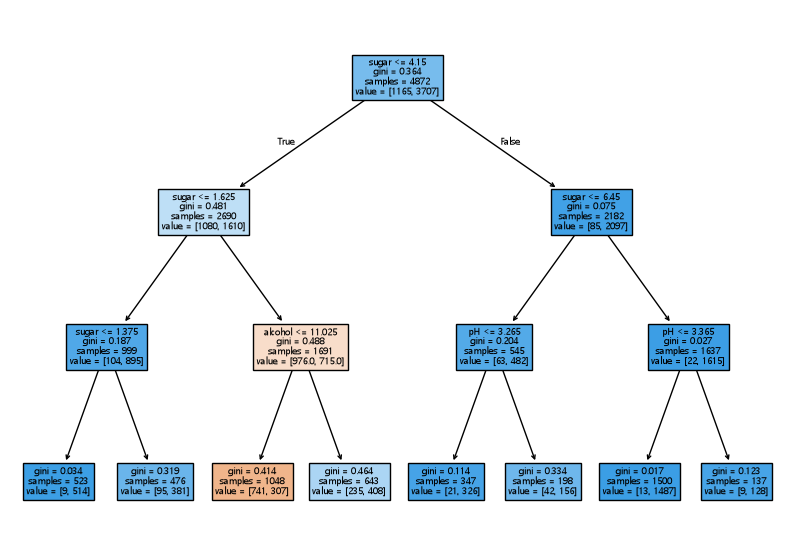

In [37]:
# 그래프 지원
plt.figure(figsize=(10,7))
plot_tree(dt,max_depth=3,filled=True,feature_names=['alcohol', 'sugar', 'pH'])
plt.show()

In [33]:
wine.columns

Index(['alcohol', 'sugar', 'pH', 'class'], dtype='str')

In [38]:
# 각 특성중에 어떤 특성이 분류에 가장 영향을 주는지 알수있음
# 'alcohol', 'sugar', 'pH'
print(dt.feature_importances_)

[0.12871631 0.86213285 0.00915084]


In [39]:
print('train정확도:',dt.score(train_data,train_label))
print('test정확도:',dt.score(test_data,test_label))

train정확도: 0.8499589490968801
test정확도: 0.8363076923076923
